# RecGym Dataset Exploration

### Import libraries and load data

In [4]:
import pandas as pd

### Load dataset

In [25]:
df = pd.read_csv("data/RecGym.csv")

### Inspect Dataset

In [16]:
print(df.shape) # (No. of Rows, No. of Columns)

(4703320, 11)


In [18]:
print(df.columns.tolist()) # The column names in the dataset

['Subject', 'Position', 'Session', 'A_x', 'A_y', 'A_z', 'G_x', 'G_y', 'G_z', 'C_1', 'Workout']


In [17]:
print(df.dtypes) # The data types of each column

Subject       int64
Position        str
Session       int64
A_x         float64
A_y         float64
A_z         float64
G_x         float64
G_y         float64
G_z         float64
C_1         float64
Workout         str
dtype: object


In [21]:
print(df.head()) # Show first couple rows of the dataset

   Subject Position  Session       A_x       A_y       A_z       G_x  \
0        1    wrist        1  0.501125  0.500625  0.500500  0.500156   
1        1    wrist        1  0.500250  0.499750  0.501250  0.499531   
2        1    wrist        1  0.500250  0.499375  0.501875  0.499613   
3        1    wrist        1  0.499625  0.499750  0.500875  0.499494   
4        1    wrist        1  0.500000  0.499000  0.501000  0.499650   

        G_y       G_z       C_1 Workout  
0  0.499962  0.500313  0.501227    Null  
1  0.500550  0.500081  0.501584    Null  
2  0.500231  0.500119  0.501508    Null  
3  0.500350  0.500588  0.502032    Null  
4  0.500588  0.499769  0.501756    Null  


In [26]:
print(df['Workout'].unique()) # Show all unique values in the Workout column

<StringArray>
[        'Null',      'LegCurl',        'Squat',     'Adductor',
     'LegPress',      'ArmCurl',   'BenchPress', 'RopeSkipping',
      'Walking',      'Running', 'StairClimber',       'Riding']
Length: 12, dtype: str


In [ ]:
print(df['Workout'].value_counts()) # Show number of rows each workout shows up in

Workout
Null            2607111
Walking          283040
StairClimber     280012
Riding           263124
Squat            251788
Running          215231
LegPress         165790
ArmCurl          159626
Adductor         145107
BenchPress       141630
LegCurl          137735
RopeSkipping      53126
Name: count, dtype: int64


In [ ]:
print(df['Workout'].value_counts()['Null'])
print(f"{df['Workout'].value_counts(normalize=True)['Null'] * 100}%")

2607111
55.431291087997415%


In [45]:
print(df.isna().values.any())

False


## Initial Findings
- The data has ~4.7 million rows and 11 columns

- A_(x,y,z) correspond to the accelerometer readings

- G_(x,y,z) correspond to the gyroscope readings

- C_1 represents the capacitive sensor readings

- The dataset contains 11 different workouts and 1 'Null' activity label for periods where the participant is not currently exercising. 

- 55.43% of the readings belong to the 'Null' class indicating a significant class imbalance

- No missing values were detected

### Explore Subject and Position

In [ ]:
print(df['Subject'].unique()) # See how many participants are in the dataset

[ 1  2  3  4  5  6  7  8  9 10]


In [ ]:
print(df['Position'].unique()) # Position of sensors in the dataset

<StringArray>
['wrist', 'leg', 'pocket']
Length: 3, dtype: str


In [10]:
print(df['Position'].value_counts()['wrist'])
print(df['Position'].value_counts()['leg'])
print(df['Position'].value_counts()['pocket'])


1625960
1476320
1601040


In [ ]:
print(pd.crosstab(df['Workout'], df['Position']))

Position         leg  pocket   wrist
Workout                             
Adductor       43197   50510   51400
ArmCurl        48788   55640   55198
BenchPress     43712   48627   49291
LegCurl        42603   47316   47816
LegPress       51507   56707   57576
Null          827165  887009  892937
Riding         83437   87801   91886
RopeSkipping   16350   17875   18901
Running        67947   72796   74488
Squat          76200   86272   89316
StairClimber   86900   95080   98032
Walking        88514   95407   99119


## Findings

All 12 workout labels are represented across the 3 sensor positions (wrist, leg, pocket). The sample counts are balanced across positions but the Null class is larger than the others.

### Exploring Session

In [15]:
print(df['Session'].unique())

[1 2 3 4 5]


In [16]:
print(pd.crosstab(df['Subject'], df['Session']))

Session       1       2       3       4      5
Subject                                       
1        157240   51600   90440   67120  67440
2        178520  109360  115560   93400  80720
3        121880  103400   99040   76160  78920
4        126640   71840   83760   86560  85760
5        103800   80240  117760   71400  94160
6         76880  145760   65160  108000  76600
7        160120   87200   67560   85800  97160
8        123400   80720   77880   90080  82560
9        108240   82520   85160   76560  80320
10        88960   75640  131840   65080  71400


In [21]:
filtered_df = df[df['Subject'] == 1]

print(pd.crosstab(filtered_df['Session'], filtered_df['Workout']))

Workout  Adductor  ArmCurl  BenchPress  LegCurl  LegPress   Null  Riding  \
Session                                                                    
1            5560     5967        5080     5550      5595  87952    3641   
2            1688     1644        1845     1615      1564  26947    3193   
3            2922     2761        2776     3129      2791  43989    7217   
4            1776     1748        2272     1641      2011  34949    5282   
5            1885     1692        2312     1941      2930  33179    5111   

Workout  RopeSkipping  Running  Squat  StairClimber  Walking  
Session                                                       
1                1013     9433  14699          6341     6409  
2                 570     2894   2949          3089     3602  
3                1367     5213   4414          6859     7002  
4                 647     3851   3138          4875     4930  
5                 996     4030   3197          4646     5521  


In [22]:
filtered_df = filtered_df[filtered_df['Session'] == 1]

print(filtered_df.head(50))

    Subject Position  Session       A_x       A_y       A_z       G_x  \
0         1    wrist        1  0.501125  0.500625  0.500500  0.500156   
1         1    wrist        1  0.500250  0.499750  0.501250  0.499531   
2         1    wrist        1  0.500250  0.499375  0.501875  0.499613   
3         1    wrist        1  0.499625  0.499750  0.500875  0.499494   
4         1    wrist        1  0.500000  0.499000  0.501000  0.499650   
5         1    wrist        1  0.499625  0.499625  0.501000  0.499494   
6         1    wrist        1  0.500750  0.500500  0.500250  0.499688   
7         1    wrist        1  0.500625  0.498500  0.502125  0.499219   
8         1    wrist        1  0.500625  0.499625  0.501250  0.499025   
9         1    wrist        1  0.500000  0.498625  0.502250  0.502381   
10        1    wrist        1  0.499250  0.498750  0.501750  0.503319   
11        1    wrist        1  0.498250  0.500875  0.501125  0.499337   
12        1    wrist        1  0.497250  0.500250  

In [ ]:
filtered_df = filtered_df[filtered_df['Workout'] != 'Null']

print(filtered_df.head(50))

     Subject Position  Session       A_x       A_y       A_z       G_x  \
476        1    wrist        1  0.499875  0.500375  0.501500  0.499337   
477        1    wrist        1  0.503000  0.498250  0.501000  0.500194   
478        1    wrist        1  0.498500  0.501250  0.500750  0.497069   
479        1    wrist        1  0.499750  0.499625  0.501125  0.498787   
480        1    wrist        1  0.498625  0.498625  0.502375  0.498244   
481        1    wrist        1  0.500125  0.500250  0.502125  0.499650   
482        1    wrist        1  0.500875  0.499625  0.501875  0.499569   
483        1    wrist        1  0.500500  0.499250  0.500625  0.499806   
484        1    wrist        1  0.500750  0.499250  0.501625  0.499844   
485        1    wrist        1  0.502250  0.497750  0.500750  0.499650   
486        1    wrist        1  0.502625  0.501875  0.499375  0.502537   
487        1    wrist        1  0.494375  0.502625  0.499625  0.496681   
488        1    wrist        1  0.5000

In [26]:
print(df.loc[470:485, ['Position', 'Workout']])

    Position  Workout
470    wrist     Null
471    wrist     Null
472    wrist     Null
473    wrist     Null
474    wrist     Null
475    wrist     Null
476    wrist  LegCurl
477    wrist  LegCurl
478    wrist  LegCurl
479    wrist  LegCurl
480    wrist  LegCurl
481    wrist  LegCurl
482    wrist  LegCurl
483    wrist  LegCurl
484    wrist  LegCurl
485    wrist  LegCurl


### Visualize sensor readings for different exercises

In [28]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [37]:
filtered_df = df[(df['Subject'] == 1) 
                 & (df['Session'] == 1)
                 & (df['Position'] == 'wrist')
                 & (df['Workout'] == 'ArmCurl')]

print(filtered_df.head())

       Subject Position  Session       A_x       A_y       A_z       G_x  \
16148        1    wrist        1  0.515250  0.506625  0.499000  0.492150   
17989        1    wrist        1  0.499375  0.500750  0.500125  0.498206   
17990        1    wrist        1  0.498500  0.504250  0.502625  0.492419   
17991        1    wrist        1  0.503000  0.494625  0.504125  0.487187   
17992        1    wrist        1  0.499125  0.495625  0.496125  0.496912   

            G_y       G_z       C_1  Workout  
16148  0.504881  0.501637  0.506615  ArmCurl  
17989  0.498244  0.500469  0.500021  ArmCurl  
17990  0.494494  0.504650  0.499183  ArmCurl  
17991  0.496875  0.502306  0.499378  ArmCurl  
17992  0.490700  0.504062  0.501606  ArmCurl  


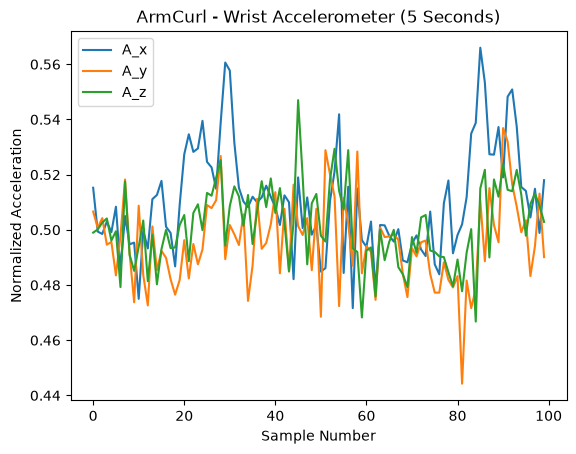

In [44]:
plt.plot(range(100), filtered_df['A_x'].head(100), label="A_x")
plt.plot(range(100), filtered_df['A_y'].head(100), label="A_y")
plt.plot(range(100), filtered_df['A_z'].head(100), label="A_z")

plt.xlabel("Sample Number")
plt.ylabel("Normalized Acceleration")

plt.title("ArmCurl - Wrist Accelerometer (5 Seconds)")
plt.legend()
plt.show()

In [ ]:
filtered_df = df[(df['Subject'] == 1) 
                 & (df['Session'] == 1)
                 & (df['Position'] == 'wrist')
                 & (df['Workout'] == 'LegCurl')]

print(filtered_df.head())

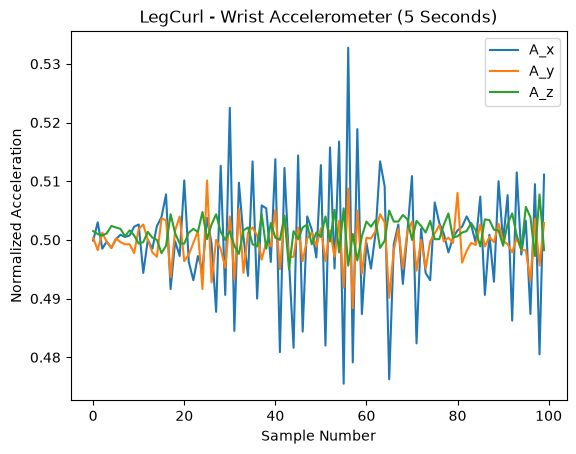

In [46]:
plt.plot(range(100), filtered_df['A_x'].head(100), label="A_x")
plt.plot(range(100), filtered_df['A_y'].head(100), label="A_y")
plt.plot(range(100), filtered_df['A_z'].head(100), label="A_z")
plt.xlabel("Sample Number")
plt.ylabel("Normalized Acceleration")
plt.title("LegCurl - Wrist Accelerometer (5 Seconds)")
plt.legend()
plt.show()

## Findings
- The sampling rate is 20hz per second
- Compared 5 seconds of wrist accelerometer readings for ArmCurl and LegCurl. ArmCurl showed larger fluctuations across multiple accelerometer the x and y axes while LegCurl readings were more stable along the y and z axes.